In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "official").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_FILE = PROJECT_ROOT / "experiments" / "datasets" / "exchange_rate.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset file:", DATASET_FILE)
print("File exists:", DATASET_FILE.exists())

Project root: d:\TVCFORMER
Dataset file: d:\TVCFORMER\experiments\datasets\exchange_rate.csv
File exists: True


In [3]:
df = pd.read_csv(DATASET_FILE)

print("Dataset: Exchange Rate")
print("Shape:", df.shape)
print("Column names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())

Dataset: Exchange Rate
Shape: (7588, 9)
Column names: ['date', '0', '1', '2', '3', '4', '5', '6', 'OT']

Data types:
date     object
0       float64
1       float64
2       float64
3       float64
4       float64
5       float64
6       float64
OT      float64
dtype: object

First 5 rows:


,date,0,1,2,3,4,5,6,OT
0,1990/1/1 0:00,0.7855,1.6110,0.861698,0.634196,0.211242,0.006838,0.525486,0.5930
1,1990/1/2 0:00,0.7818,1.6100,0.861104,0.633513,0.211242,0.006863,0.523972,0.5940
2,1990/1/3 0:00,0.7867,1.6293,0.861030,0.648508,0.211242,0.006975,0.526316,0.5973
3,1990/1/4 0:00,0.7860,1.6370,0.862069,0.650618,0.211242,0.006953,0.523834,0.5970
4,1990/1/5 0:00,0.7849,1.6530,0.861995,0.656254,0.211242,0.006940,0.527426,0.5985


In [4]:
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\nMissing percentage (%):")
display((df.isna().mean() * 100).to_frame("missing_percent"))

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Missing values:


,missing_count
date,0
0,0
1,0
2,0
3,0
4,0
5,0
6,0
OT,0



Missing percentage (%):


,missing_percent
date,0.0
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
5,0.0
6,0.0
OT,0.0



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,7588,7588,1990/1/1 0:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,7588.0,NaN,NaN,NaN,0.776974,0.13662,0.483297,0.701422,0.761377,0.873477,1.102536
1,7588.0,NaN,NaN,NaN,1.634105,0.161544,1.211534,1.532887,1.606574,1.707646,2.109
2,7588.0,NaN,NaN,NaN,0.821811,0.117123,0.618582,0.727901,0.811582,0.920394,1.091524
3,7588.0,NaN,NaN,NaN,0.848146,0.168874,0.548617,0.696864,0.813959,1.014018,1.374079
4,7588.0,NaN,NaN,NaN,0.142833,0.023996,0.109292,0.120814,0.145212,0.159948,0.237954
5,7588.0,NaN,NaN,NaN,0.009343,0.001458,0.006254,0.008331,0.009151,0.009995,0.013202
6,7588.0,NaN,NaN,NaN,0.669673,0.082836,0.523834,0.593287,0.662767,0.731835,0.832556
OT,7588.0,NaN,NaN,NaN,0.654418,0.115292,0.393153,0.566,0.669187,0.734901,0.882379


In [5]:
duplicate_rows = df.duplicated().sum()

print("Số dòng trùng lặp hoàn toàn:", duplicate_rows)

if duplicate_rows > 0:
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("Không có dòng trùng lặp hoàn toàn.")

Số dòng trùng lặp hoàn toàn: 0
Không có dòng trùng lặp hoàn toàn.


In [6]:
if "date" in df.columns:
    dates = pd.to_datetime(df["date"], errors="coerce")
    duplicated_dates = dates.duplicated(keep=False)

    print("Số ngày không hợp lệ:", dates.isna().sum())
    print("Số dòng có timestamp trùng:", duplicated_dates.sum())
    print("Số timestamp trùng khác nhau:", dates[duplicated_dates].nunique())

    if duplicated_dates.any():
        display(
            df.loc[duplicated_dates]
            .assign(date=dates[duplicated_dates])
            .sort_values("date")
            .head(10)
        )

Số ngày không hợp lệ: 0
Số dòng có timestamp trùng: 0
Số timestamp trùng khác nhau: 0


In [7]:
duplicate_values = df.apply(
    lambda col: int(col.duplicated().sum())
)

print("Số giá trị lặp lại theo từng cột:")
display(duplicate_values.to_frame("duplicate_count"))

Số giá trị lặp lại theo từng cột:


,duplicate_count
date,0
0,2258
1,1881
2,1954
3,1930
4,4455
5,3978
6,2694
OT,2355


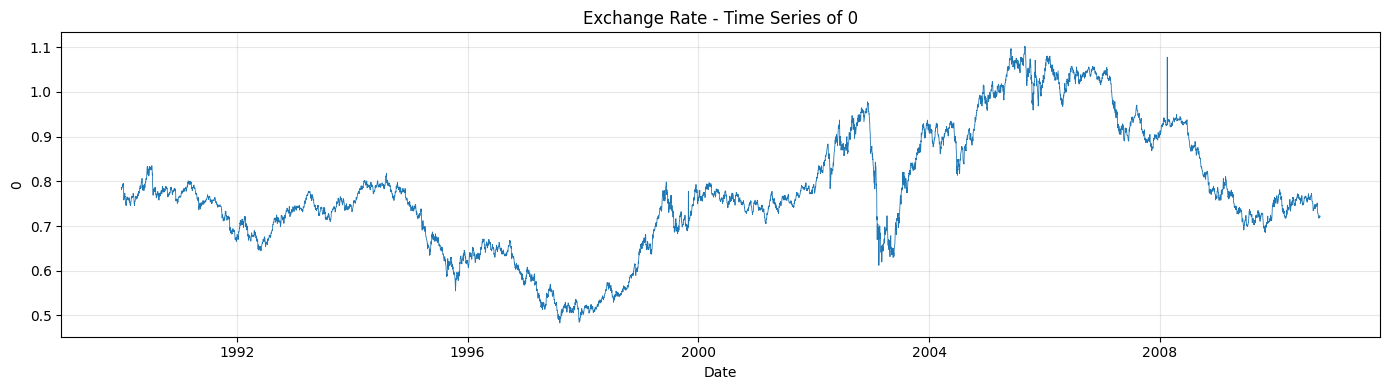

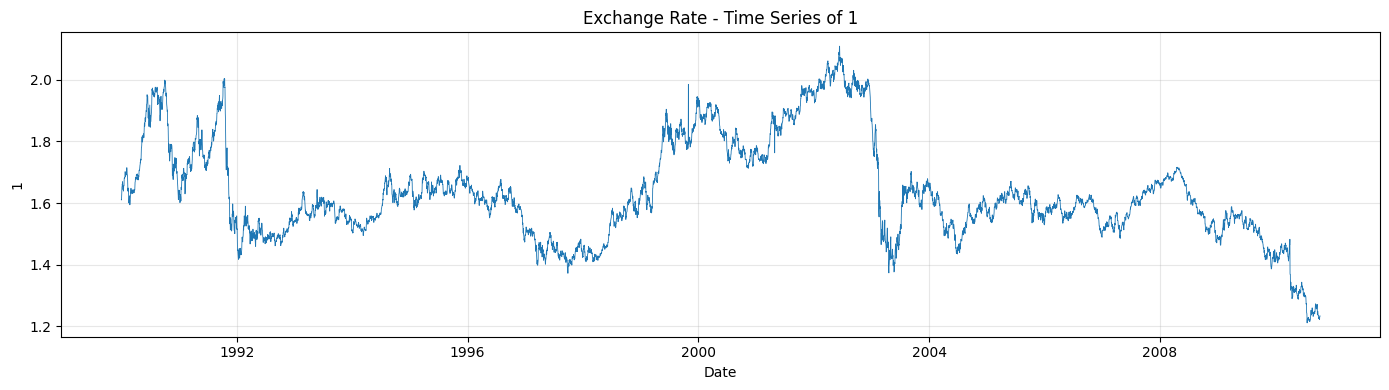

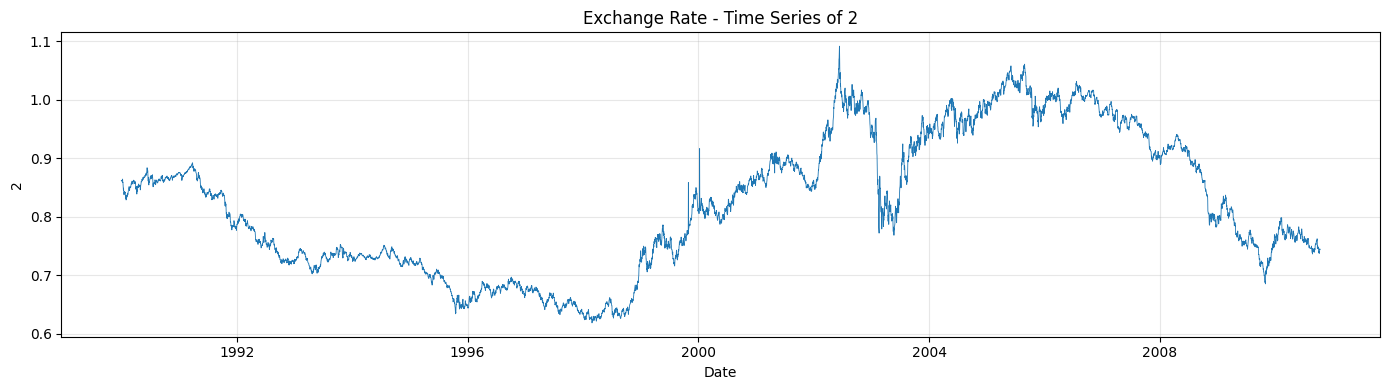

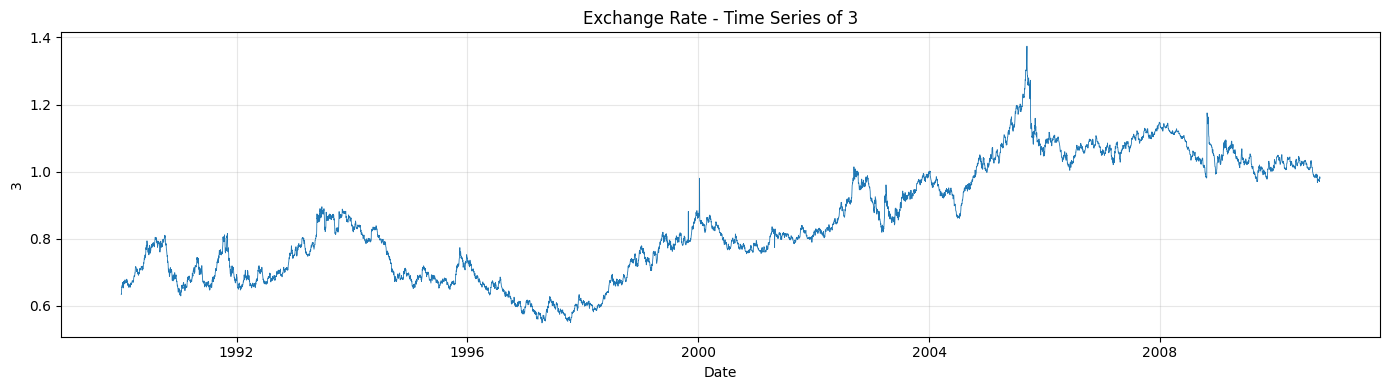

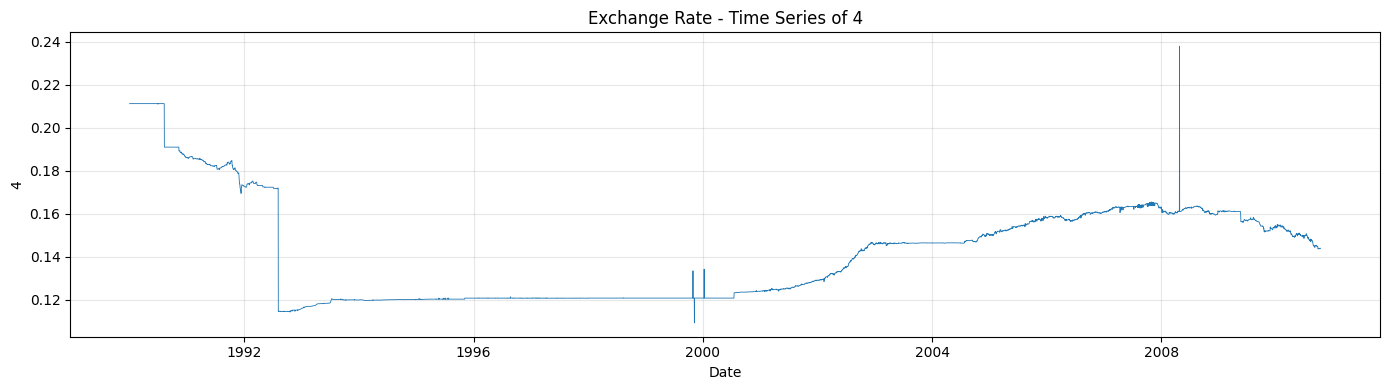

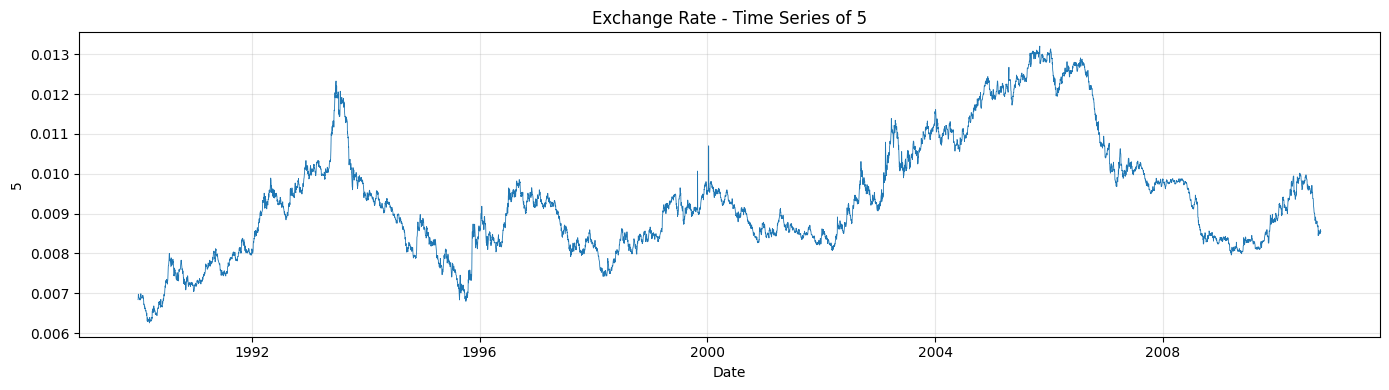

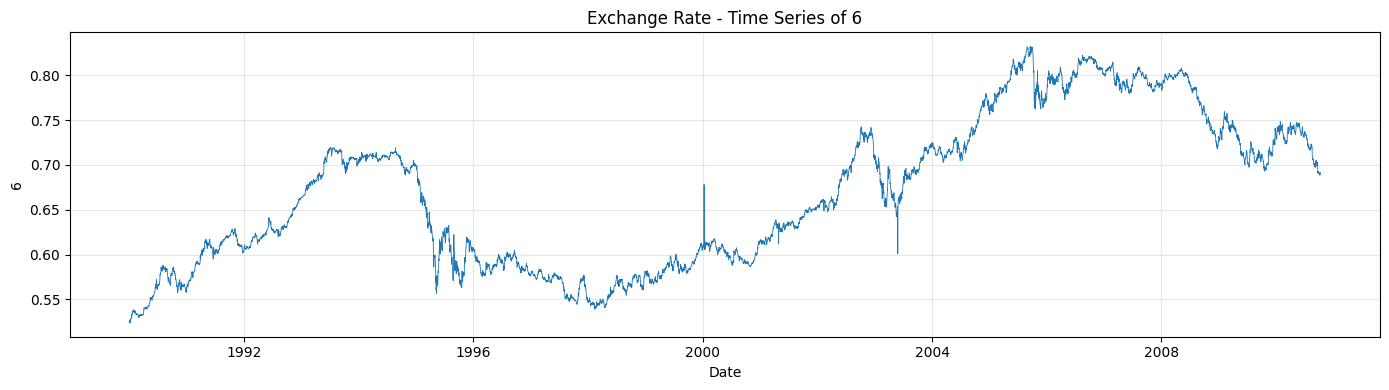

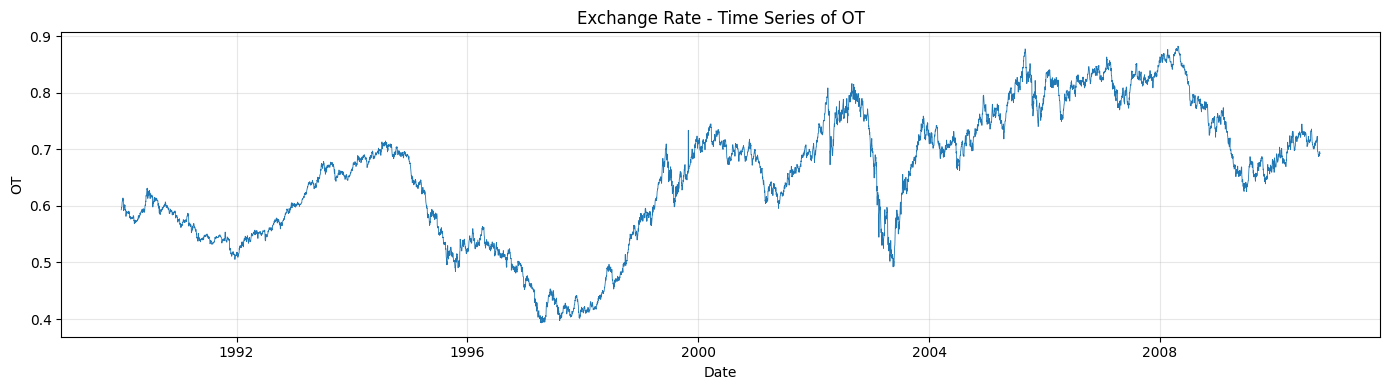

In [8]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
numeric_cols = df.select_dtypes(include="number").columns.tolist()

for col in numeric_cols:
    data = df.dropna(subset=["date", col]).sort_values("date")

    plt.figure(figsize=(14, 4))
    plt.plot(data["date"], data[col], linewidth=0.6)
    plt.title(f"Exchange Rate - Time Series of {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

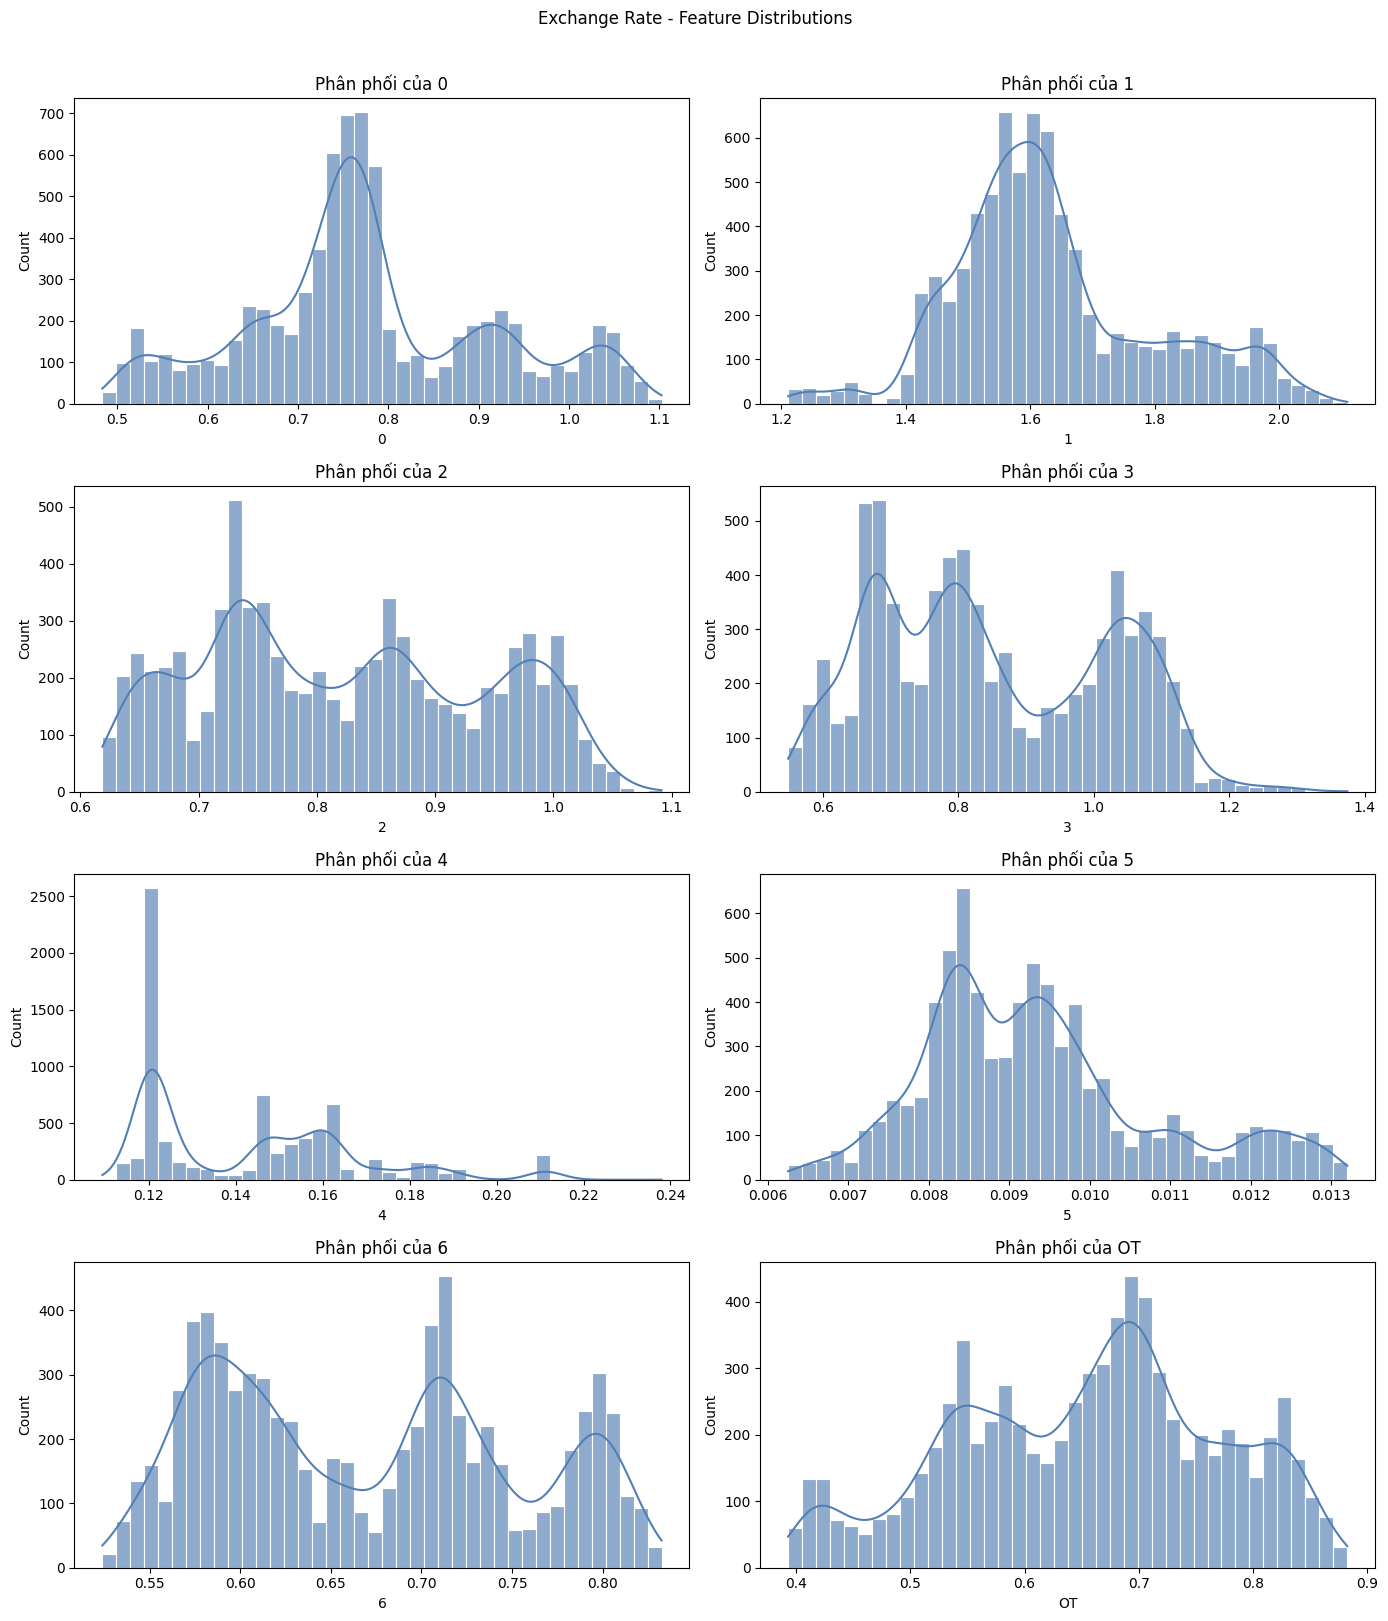

In [13]:

# Exchange Rate - Feature Distributions with KDE
import seaborn as sns
import matplotlib.pyplot as plt
import math

numeric_cols = df.select_dtypes(include="number").columns.tolist()

n_cols = 2
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=40,
        kde=True,
        color="#527FB5",
        edgecolor="white",
        alpha=0.65,
        ax=axes[i]
    )
    axes[i].set_title(f"Phân phối của {col}")

for i in range(len(numeric_cols), len(axes)):
    axes[i].set_visible(False)

fig.suptitle("Exchange Rate - Feature Distributions", y=1.01)
plt.tight_layout()
plt.show()

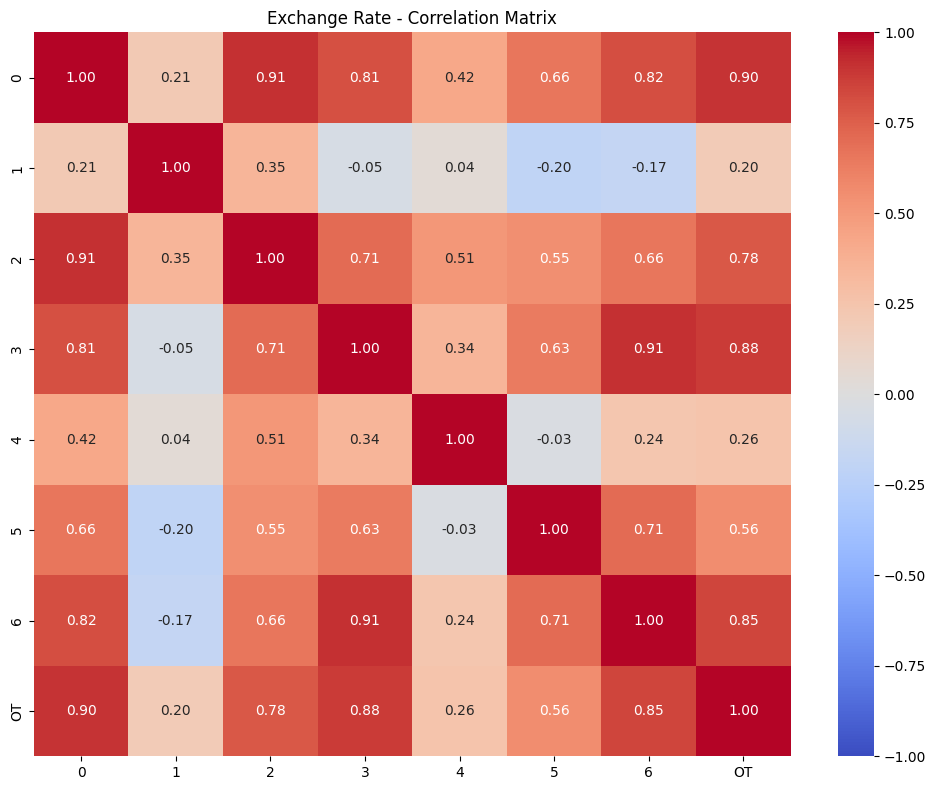

In [10]:
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Exchange Rate - Correlation Matrix")
plt.tight_layout()
plt.show()

In [11]:
print("=" * 60)
print("EXCHANGE RATE DATASET OVERVIEW")
print("=" * 60)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

dates = pd.to_datetime(df["date"], errors="coerce")

print("Start date:", dates.min())
print("End date:", dates.max())
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget configuration:")
print("Dataset này không có cột OT theo cấu trúc thông thường.")
print("Cần kiểm tra data loader và cấu hình chính thức để xác định target.")

EXCHANGE RATE DATASET OVERVIEW
Shape: (7588, 9)
Columns: ['date', '0', '1', '2', '3', '4', '5', '6', 'OT']
Start date: 1990-01-01 00:00:00
End date: 2010-10-10 00:00:00
Missing values: 0
Duplicate rows: 0

Target configuration:
Dataset này không có cột OT theo cấu trúc thông thường.
Cần kiểm tra data loader và cấu hình chính thức để xác định target.
